# Part B  -  Themes in complaint narratives

What themes live in the narratives beyond the official product/issue taxonomy, how do they drift over time, and do relief rates differ by theme? Classical topic models (NMF, LDA) are benchmarked against embedding clustering (k-means, UMAP + HDBSCAN), and the chosen themes are fed back into the Part A model (run `part_a_supervised.ipynb` first).

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import umap
from lightgbm import LGBMClassifier
from matplotlib.ticker import PercentFormatter
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfTransformer
from sklearn.metrics import adjusted_rand_score, average_precision_score, normalized_mutual_info_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

%run ./data_preparation.ipynb

plt.rcParams["figure.figsize"] = (8, 3.5)
SEED = 0
FIG, RES = Path("figures"), Path("results")

### Stratified sample

Up to 1,000 closed complaints per product group  times  year cell (2015-2025), with exact duplicates (after normalizing case and punctuation) dropped. `weight` = cell population ÷ documents kept, used to reweight results back to the real complaint mix.

In [2]:
N_PER_CELL, CELL = 1000, ["product_group", "year"]
SAMPLE = Path("data/part_b_sample.parquet")

if SAMPLE.exists():
    docs = pd.read_parquet(SAMPLE)
else:
    meta = read_exports()
    meta = meta[meta["year"].between(2015, 2025)]
    picked = meta.sample(frac=1, random_state=SEED).groupby(CELL).head(N_PER_CELL)
    docs = read_exports(["Issue", "Company", "Consumer complaint narrative"],
                        keep=lambda d: d["Complaint ID"].isin(picked["Complaint ID"]))
    docs["text"] = clean(docs.pop("Consumer complaint narrative"))
    key = docs["text"].str.lower().str.replace(r"[^a-z]", "", regex=True)
    print(f"dropping {key.duplicated().sum():,} duplicate and {(key == '').sum()} empty narratives")
    docs = docs[~key.duplicated() & (key != "")].reset_index(drop=True)
    docs = docs.join((meta.groupby(CELL).size() / docs.groupby(CELL).size()).rename("weight"), on=CELL)
    docs.to_parquet(SAMPLE, index=False)

len(docs)

dropping 2,718 duplicate and 5 empty narratives


97585

### Topic models: NMF vs. LDA

Uni- and bigrams with English stop words plus brand names (otherwise several topics are just "Wells Fargo" or "Bank of America", which would make cross-company comparisons circular). Topic counts are compared with NPMI coherence of each topic's top-10 words.

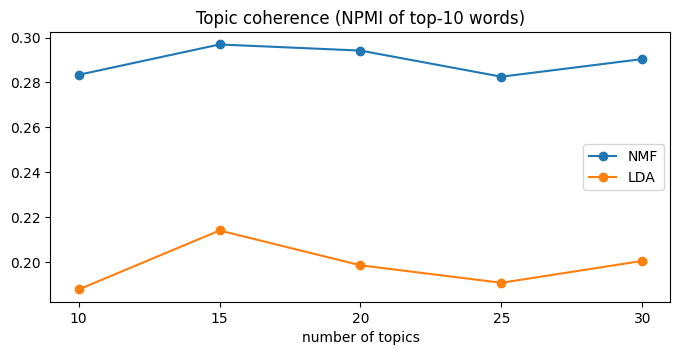

In [3]:
BRANDS = {"wells", "fargo", "chase", "jpmorgan", "boa", "america", "citi", "citibank", "synchrony", "navient",
          "paypal", "coinbase", "equifax", "experian", "transunion"}
cv = CountVectorizer(token_pattern=r"(?u)\b[a-z]{3,}\b", stop_words=list(ENGLISH_STOP_WORDS | BRANDS),
                     ngram_range=(1, 2), min_df=20, max_df=0.5, max_features=20_000)
counts = cv.fit_transform(docs["text"])
tfidf = TfidfTransformer(sublinear_tf=True).fit_transform(counts)
vocab = cv.get_feature_names_out()
present = (counts > 0).astype(np.float32).tocsc()


def npmi(components, n_top=10):
    """Mean NPMI over pairs of each topic's top words, from document co-occurrence."""
    scores = []
    for comp in components:
        top = present[:, np.argsort(comp)[::-1][:n_top]]
        p = (top.T @ top).toarray() / present.shape[0]
        i, j = np.triu_indices(n_top, 1)
        scores.append(np.mean(np.log((p[i, j] + 1e-12) / (p[i, i] * p[j, j])) / -np.log(p[i, j] + 1e-12)))
    return np.mean(scores)


KS = [10, 15, 20, 25, 30]
nmfs = {k: NMF(k, init="nndsvda", random_state=SEED, max_iter=400).fit(tfidf) for k in KS}
ldas = {k: LatentDirichletAllocation(k, learning_method="online", batch_size=4096, random_state=SEED, n_jobs=4).fit(counts)
        for k in KS}
coherence = pd.DataFrame({"NMF": {k: npmi(m.components_) for k, m in nmfs.items()},
                          "LDA": {k: npmi(m.components_) for k, m in ldas.items()}})
coherence.to_csv(RES / "part_b_coherence.csv")
ax = coherence.plot(marker="o", xticks=KS, title="Topic coherence (NPMI of top-10 words)")
ax.set_xlabel("number of topics")
plt.savefig(FIG / "b_coherence.png", dpi=150, bbox_inches="tight")

In [4]:
K = int(coherence["NMF"].idxmax())
nmf = nmfs[K]
docs["theme"] = nmf.transform(tfidf).argmax(axis=1)


def label(component, n=3):
    """Top distinct terms of a topic, skipping terms nested in ones already picked."""
    words = []
    for w in vocab[np.argsort(component)[::-1]]:
        if not any(w in v or v in w for v in words):
            words.append(w)
        if len(words) == n:
            return " / ".join(words).replace("dollaramount", "$amount")


THEMES = [label(c) for c in nmf.components_]
pd.DataFrame({"theme": THEMES, "share": docs["theme"].value_counts(normalize=True).sort_index(),
              "top words": [", ".join(vocab[np.argsort(c)[::-1][:10]]) for c in nmf.components_]}).round(3)

,theme,share,top words
theme,,,
0,told / said / just,0.052,"told, said, just, called, money, help, know, p..."
1,consumer / reporting / information,0.060,"consumer, reporting, information, act, fcra, v..."
2,payment / late / make,0.081,"payment, late, payments, late payment, make, m..."
3,report / credit / removed,0.086,"report, credit, credit report, reporting, remo..."
4,section / states / consumer reporting,0.008,"section, section states, states, consumer repo..."
5,debt / collection / company,0.073,"debt, collection, collect, company, agency, co..."
6,car / vehicle / loan,0.069,"car, vehicle, loan, finance, dealership, title..."
7,loans / student / payments,0.077,"loans, loan, student, student loan, student lo..."
8,card / credit / charges,0.097,"card, credit card, credit, charges, cards, cha..."


### Embedding clusters: k-means vs. UMAP + HDBSCAN

Same `all-MiniLM-L6-v2` embeddings as Part A. k-means uses the NMF topic count; HDBSCAN runs on a 5-d UMAP projection and leaves low-density documents as noise.

In [5]:
EMB = Path("data/part_b_embeddings.npy")
if not EMB.exists():
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer("all-MiniLM-L6-v2")
    np.save(EMB, st_model.encode(docs["text"].tolist(), batch_size=256, normalize_embeddings=True))
emb = np.load(EMB)

kmeans = KMeans(K, n_init=3, random_state=SEED).fit(emb)
umap5 = umap.UMAP(n_components=5, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=SEED,
                  n_jobs=1).fit_transform(emb)
hdb = HDBSCAN(min_cluster_size=500, min_samples=10, copy=True).fit_predict(umap5)
labels = {"NMF": docs["theme"].to_numpy(), "LDA": ldas[K].transform(counts).argmax(axis=1),
          "k-means": kmeans.labels_, "UMAP+HDBSCAN": hdb}

In [6]:
def stability(fit_predict, n_boot=3):
    """Mean pairwise ARI between labelings from models refit on bootstrap resamples."""
    rng = np.random.default_rng(SEED)
    runs = [fit_predict(rng.choice(len(docs), len(docs))) for _ in range(n_boot)]
    return np.mean([adjusted_rand_score(a, b) for a, b in combinations(runs, 2)])


sub = np.random.default_rng(SEED).choice(len(docs), 10_000, replace=False)
rows = []
for name, lab in labels.items():
    ok = lab >= 0
    rows.append({"method": name, "clusters": len(np.unique(lab[ok])), "noise": 1 - ok.mean(),
                 "NMI product": normalized_mutual_info_score(docs["product_group"][ok], lab[ok]),
                 "NMI issue": normalized_mutual_info_score(docs["Issue"][ok], lab[ok]),
                 "silhouette": silhouette_score(emb[sub][ok[sub]], lab[sub][ok[sub]], metric="cosine")})
comparison = pd.DataFrame(rows).set_index("method")
comparison.loc["NMF", "stability (ARI)"] = stability(
    lambda i: NMF(K, init="nndsvda", random_state=SEED, max_iter=400).fit(tfidf[i]).transform(tfidf).argmax(axis=1))
comparison.loc["k-means", "stability (ARI)"] = stability(
    lambda i: KMeans(K, n_init=3, random_state=SEED).fit(emb[i]).predict(emb))
comparison.to_csv(RES / "part_b_comparison.csv")
comparison.round(3)

,clusters,noise,NMI product,NMI issue,silhouette,stability (ARI)
method,,,,,,
NMF,15,0.000,0.340,0.272,0.022,0.717
LDA,15,0.000,0.313,0.270,0.008,NaN
k-means,15,0.000,0.375,0.302,0.063,0.730
UMAP+HDBSCAN,32,0.434,0.476,0.406,0.090,NaN


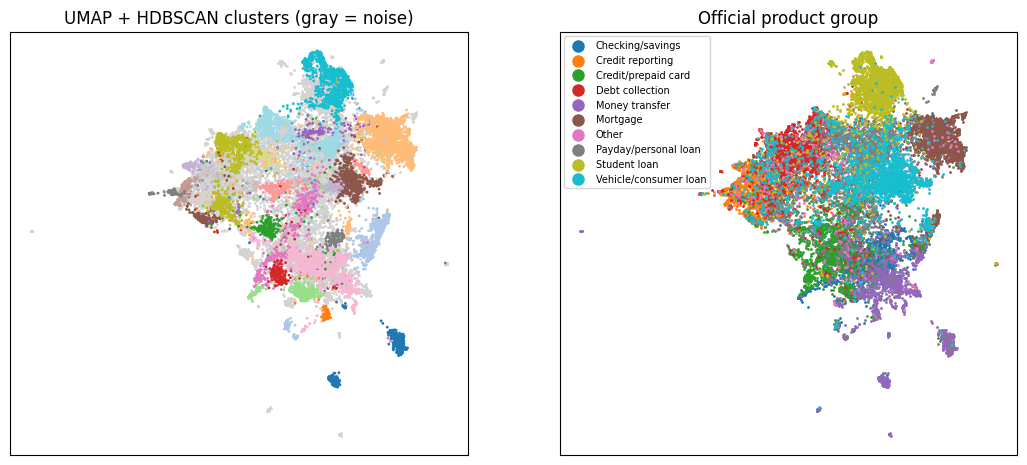

In [7]:
plot = np.random.default_rng(SEED).choice(len(docs), 20_000, replace=False)
xy = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED,
               n_jobs=1).fit_transform(emb[plot])
noise = hdb[plot] < 0
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(*xy[noise].T, s=1, c="lightgray")
axes[0].scatter(*xy[~noise].T, s=1, c=hdb[plot][~noise], cmap="tab20")
axes[0].set_title("UMAP + HDBSCAN clusters (gray = noise)")
for group, idx in docs.iloc[plot].groupby("product_group").indices.items():
    axes[1].scatter(*xy[idx].T, s=1, label=group)
axes[1].set_title("Official product group")
axes[1].legend(markerscale=8, fontsize=7)
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.savefig(FIG / "b_umap.png", dpi=150, bbox_inches="tight")

### Themes over time and relief rates

NMF themes, reweighted to all closed narrative complaints with `weight`.

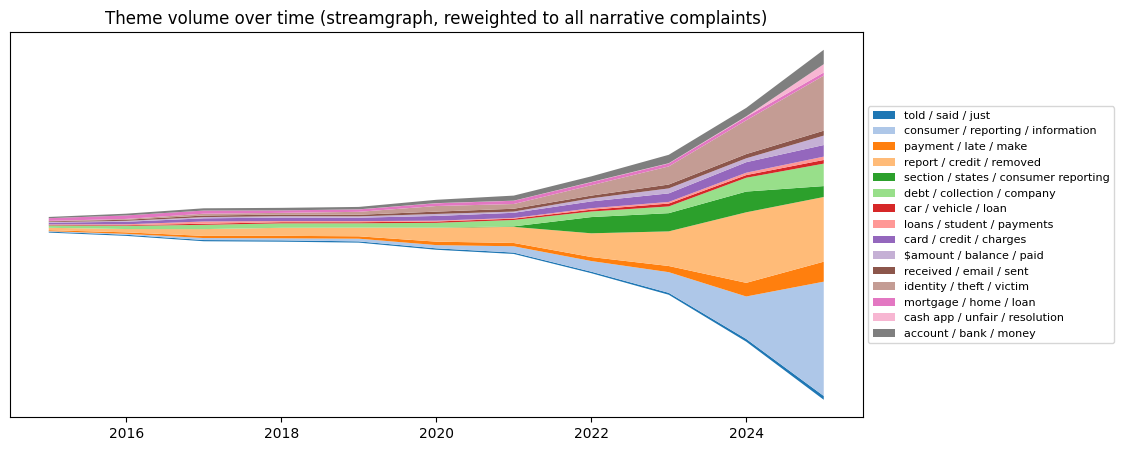

In [8]:
volume = docs.pivot_table(index="year", columns="theme", values="weight", aggfunc="sum").fillna(0)
fig, ax = plt.subplots(figsize=(11, 5))
ax.stackplot(volume.index, volume.T.to_numpy(), labels=[THEMES[t] for t in volume.columns], baseline="sym",
             colors=plt.cm.tab20.colors)
ax.set(yticks=[], title="Theme volume over time (streamgraph, reweighted to all narrative complaints)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
fig.savefig(FIG / "b_theme_streamgraph.png", dpi=150, bbox_inches="tight")

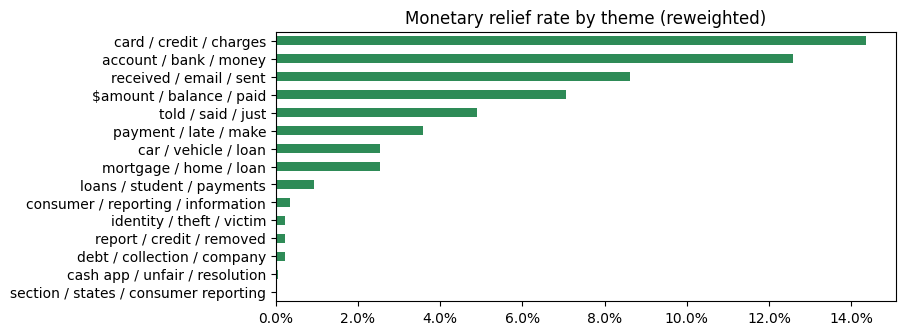

In [9]:
relief = docs.groupby("theme").apply(lambda g: np.average(g["y"], weights=g["weight"])).rename(lambda t: THEMES[t])
ax = relief.sort_values().plot.barh(color="seagreen", title="Monetary relief rate by theme (reweighted)")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("")
plt.savefig(FIG / "b_relief_by_theme.png", dpi=150, bbox_inches="tight")

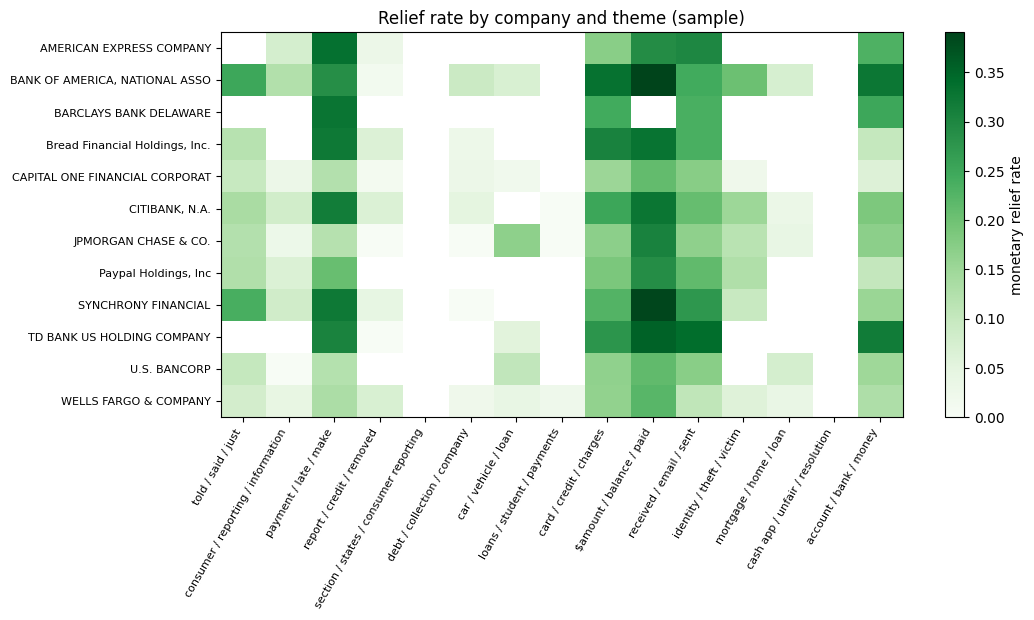

In [10]:
# Companies with the most relief outcomes in the sample; cells with fewer than 30 complaints left blank
top_cos = docs.loc[docs["y"] == 1, "Company"].value_counts().head(12).index
by_cell = docs[docs["Company"].isin(top_cos)].groupby(["Company", "theme"])["y"]
rate = by_cell.mean().where(by_cell.size() >= 30).unstack()
rate.rename(columns=lambda t: THEMES[t]).to_csv(RES / "part_b_company_theme_relief.csv")
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(rate, cmap="Greens", aspect="auto")
ax.set_xticks(range(rate.shape[1]), [THEMES[t] for t in rate.columns], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(rate)), rate.index.str[:30], fontsize=8)
fig.colorbar(im, label="monetary relief rate")
ax.set_title("Relief rate by company and theme (sample)")
fig.savefig(FIG / "b_company_theme_relief.png", dpi=150, bbox_inches="tight")

### Integration: do theme features help the Part A model?

The theme pipeline (same vectorizer and topic count) is refit on Part A's 2018-22 training text only, so no 2023-25 text leaks in. Each complaint's NMF theme weights are appended to the structured features, with the same LightGBM settings as Part A.

structured                       0.280
structured + 15 themes           0.306
structured + 20k TF-IDF terms    0.288
Name: test PR-AUC, dtype: float64

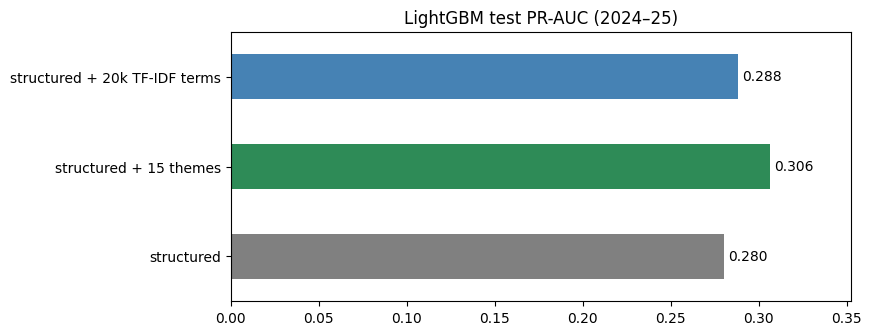

In [11]:
part_a = pd.read_parquet("data/part_a_sample.parquet")
train, test = (part_a["split"] == "train").to_numpy(), (part_a["split"] == "test").to_numpy()
themer = make_pipeline(CountVectorizer(**cv.get_params()), TfidfTransformer(sublinear_tf=True),
                       NMF(K, init="nndsvda", random_state=SEED, max_iter=400))
themes = themer.fit(part_a.loc[train, "text"]).transform(part_a["text"])
ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, dtype=np.float32)
struct = ohe.fit(part_a.loc[train, CAT_COLS].fillna("None")).transform(part_a[CAT_COLS].fillna("None"))

lift = {}
for name, X in {"structured": struct, f"structured + {K} themes": sp.hstack([struct, themes]).tocsr()}.items():
    model = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.3, class_weight="balanced", random_state=SEED, verbose=-1)
    model.fit(X[train], part_a["y"][train])
    lift[name] = average_precision_score(part_a["y"][test], model.predict_proba(X[test])[:, 1])
part_a_results = pd.read_csv(RES / "part_a_results.csv").set_index(["representation", "model"])
lift["structured + 20k TF-IDF terms"] = part_a_results.loc[("structured+tfidf", "LightGBM"), "test PR-AUC"]
lift = pd.Series(lift, name="test PR-AUC")
lift.to_csv(RES / "part_b_integration.csv")

ax = lift.plot.barh(color=["gray", "seagreen", "steelblue"], title="LightGBM test PR-AUC (2024–25)")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set_xlim(0, lift.max() * 1.15)
plt.savefig(FIG / "b_integration.png", dpi=150, bbox_inches="tight")
lift.round(3)

### Takeaways

- NMF is more coherent than LDA at every topic count (best k = 15: NPMI 0.30 vs. 0.21), and NMF and k-means are similarly stable across bootstrap refits (ARI about  0.72-0.73).
- Embedding clusters line up more with the official product labels (NMI 0.48 for HDBSCAN, which leaves 43% of documents as noise) than NMF themes do (0.34), so the NMF themes cut across the taxonomy.
- Templated campaigns form their own themes (FCRA "section … states" letters, Cash App), and the 2023-25 surge is dominated by credit-report disputes and identity-theft claims.
- Card-charge and bank-account themes get relief 13-14% of the time. Within a theme, raw relief rates differ 2-3 times  across companies (late payments: ~32% at Amex / Citi / Synchrony vs. ~12% at Capital One / Chase / Wells Fargo).
- 15 theme weights lift the structured LightGBM from 0.280 to 0.306 test PR-AUC, more than 20k raw TF-IDF terms do (0.288).
- Next: MinHash near-duplicate removal, BERTopic and HDBSCAN tuning, hand-labelling a validation sample, company comparisons adjusted for product and issue mix.

## Topic sensitivity and cluster comparisons

These fits check topic count and initialization, then compare the product mix and coverage of each method.

In [2]:
import json
import time
from threadpoolctl import threadpool_limits
from IPython.display import Image, Markdown, display

CACHE = Path("artifacts")
CACHE.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})

def show(name):
    display(pd.read_csv(RES / name))

In [3]:
def log(message):
    print(time.strftime("%H:%M:%S"), message, flush=True)

In [4]:
def savefig(name):
    plt.savefig(FIG / name, dpi=160, bbox_inches="tight", facecolor="white")
    plt.close()

In [5]:
def write_json(name, obj):
    (RES / name).write_text(json.dumps(obj, indent=2, default=lambda v: v.item() if hasattr(v, "item") else str(v)), encoding="utf-8")

In [6]:
def count_vectorizer():
    return CountVectorizer(token_pattern=r"(?u)\b[a-z]{3,}\b",stop_words=sorted(ENGLISH_STOP_WORDS | BRANDS),
        ngram_range=(1,2),min_df=20,max_df=0.5,max_features=20_000)

In [7]:
def topic_coherence(components,present):
    values=[]
    for comp in components:
        top=present[:,np.argsort(comp)[::-1][:10]]
        p=(top.T@top).toarray()/present.shape[0]
        i,j=np.triu_indices(10,1)
        values.append(np.mean(np.log((p[i,j]+1e-12)/(p[i,i]*p[j,j]))/-np.log(p[i,j]+1e-12)))
    return float(np.mean(values))

In [8]:
def unsupervised():
    import joblib
    import umap
    d=pd.read_parquet("data/part_b_sample.parquet")
    emb=np.load("data/part_b_embeddings.npy",mmap_mode="r")
    log("Fitting supplementary topic models on the original Part B sample")
    cvect=count_vectorizer();counts=cvect.fit_transform(d["text"])
    tfidf=TfidfTransformer(sublinear_tf=True).fit_transform(counts)
    vocab=cvect.get_feature_names_out()
    pd.DataFrame({"index":np.arange(len(vocab)),"feature":vocab,"field":"unsupervised_count_or_tfidf"}).to_csv(RES / "b_feature_manifest.csv",index=False)
    present=(counts>0).astype(np.float32).tocsc()
    models={};labels={};topics=[];sensitivity=[]
    for k in [10,15,20,25,30]:
        log(f"NMF sensitivity k={k}")
        nm=NMF(k,init="nndsvda",random_state=SEED,max_iter=400).fit(tfidf)
        lab=nm.transform(tfidf).argmax(axis=1)
        sensitivity.append({"k":k,"npmi":topic_coherence(nm.components_,present),
            "reconstruction_error":nm.reconstruction_err_,"product_nmi":normalized_mutual_info_score(d["product_group"],lab)})
        if k==15: models["NMF"]=nm;labels["NMF"]=lab
    pd.DataFrame(sensitivity).to_csv(RES / "b_nmf_sensitivity.csv",index=False)
    log("LDA k=15")
    lda=LatentDirichletAllocation(15,learning_method="online",batch_size=4096,random_state=SEED,n_jobs=4).fit(counts)
    models["LDA"]=lda;labels["LDA"]=lda.transform(counts).argmax(axis=1)
    log("k-means k=15")
    km=KMeans(15,n_init=3,random_state=SEED).fit(emb)
    labels["k-means"]=km.labels_
    log("5D UMAP and HDBSCAN")
    u=umap.UMAP(n_components=5,n_neighbors=15,min_dist=0.0,metric="cosine",random_state=SEED,n_jobs=1).fit_transform(emb)
    labels["UMAP+HDBSCAN"]=HDBSCAN(min_cluster_size=500,min_samples=10,copy=True,n_jobs=4).fit_predict(u)
    np.save(CACHE / "b_umap5.npy",u)
    joblib.dump({"models":models,"labels":labels,"vectorizer":cvect},CACHE / "b_models.joblib")
    pd.DataFrame({"Complaint ID":d["Complaint ID"],**labels}).to_csv(RES / "b_assignments.csv",index=False)
    rows=[]
    sub=np.random.default_rng(SEED).choice(len(d),3000,replace=False)
    for name,lab in labels.items():
        ok=lab>=0
        rows.append({"method":name,"clusters":len(np.unique(lab[ok])),"noise":float(1-ok.mean()),
            "product_nmi":normalized_mutual_info_score(d.loc[ok,"product_group"],lab[ok]),
            "issue_nmi":normalized_mutual_info_score(d.loc[ok,"Issue"],lab[ok]),
            "cosine_silhouette_3000":silhouette_score(emb[sub][ok[sub]],lab[sub][ok[sub]],metric="cosine"),
            "npmi":topic_coherence(models[name].components_,present) if name in models else None})
        # Two distinct visuals for every explored method: prevalence and product composition.
        series=pd.Series(lab).value_counts(normalize=True).sort_index()
        fig,ax=plt.subplots(figsize=(7,2.4))
        series.plot.bar(ax=ax,color="steelblue",rot=0)
        ax.set(xlabel="Theme / cluster (-1 means noise)",ylabel="Fraction of sampled complaints",title=name+": cluster sizes")
        savefig("b_"+name.lower().replace("+","_").replace("-", "")+"_sizes.png")
        tab=pd.crosstab(pd.Series(lab,name="cluster"),d["product_group"],normalize="index")
        fig,ax=plt.subplots(figsize=(7,3.6))
        im=ax.imshow(tab,aspect="auto",cmap="Blues",vmin=0,vmax=1)
        ax.set_xticks(range(len(tab.columns)),tab.columns,rotation=45,ha="right",fontsize=8)
        ax.set_yticks(range(len(tab)),tab.index,fontsize=7)
        ax.set(title=name+": product mix inside each cluster",ylabel="Theme / cluster")
        fig.colorbar(im,ax=ax,label="Within-cluster share",pad=0.02)
        savefig("b_"+name.lower().replace("+","_").replace("-", "")+"_products.png")
        tab.to_csv(RES / ("b_"+name.lower().replace("+","_").replace("-", "")+"_products.csv"))
    pd.DataFrame(rows).to_csv(RES / "b_reproduced_comparison.csv",index=False)
    for method,m in models.items():
        for j,comp in enumerate(m.components_):
            subset=d.loc[labels[method]==j]
            topics.append({"method":method,"theme":j,"n":len(subset),
                "top_terms":", ".join(vocab[np.argsort(comp)[::-1][:10]]),
                "weighted_relief":float(np.average(subset["y"],weights=subset["weight"]))})
    pd.DataFrame(topics).to_csv(RES / "b_topics.csv",index=False)
    topic_names=[", ".join(vocab[np.argsort(comp)[::-1][:3]]) for comp in models["NMF"].components_]
    d["theme"]=labels["NMF"]
    # Weights restore product/year totals, not the distribution removed by deduplication.
    rates=d.groupby("theme").apply(lambda g:np.average(g["y"],weights=g["weight"]),include_groups=False)
    fig,ax=plt.subplots(figsize=(7,3.8))
    rates.rename(index=dict(enumerate(topic_names))).sort_values().plot.barh(ax=ax,color="seagreen")
    ax.set(xlabel="Weighted monetary relief rate",ylabel="",title="NMF: relief by theme (descriptive)")
    savefig("b_nmf_relief_final.png")
    volumes=d.pivot_table(index="year",columns="theme",values="weight",aggfunc="sum").fillna(0)
    volumes.to_csv(RES / "b_theme_volume.csv")
    rates.to_csv(RES / "b_theme_relief.csv")
    # Representative documents for a qualitative inspection, with no invented human ratings.
    reps=[]
    weights=models["NMF"].transform(tfidf)
    for j in range(15):
        for idx in np.argsort(weights[:,j])[-2:][::-1]:
            reps.append({"theme":j,"Complaint ID":d.iloc[idx]["Complaint ID"],"text":d.iloc[idx]["text"],"top_terms":topic_names[j]})
    pd.DataFrame(reps).to_json(CACHE / "b_representatives.json",orient="records",indent=2)
    # Variation by initialization, keeping the vocabulary fixed, isolates fitting instability.
    stable=[]
    for seed in [0,1,2]:
        m=NMF(15,init="random",random_state=seed,max_iter=400).fit(tfidf)
        lab=m.transform(tfidf).argmax(axis=1)
        stable.append({"seed":seed,"npmi":topic_coherence(m.components_,present),
            "ari_to_nndsvda_seed0":adjusted_rand_score(labels["NMF"],lab)})
    pd.DataFrame(stable).to_csv(RES / "b_seed_sensitivity.csv",index=False)
    log("Unsupervised supplement finished")

In [9]:
if not (RES / "b_reproduced_comparison.csv").exists():
    with threadpool_limits(limits=4):
        unsupervised()

## Topic sensitivity

NMF is selected for readable topic summaries. Silhouette, NMI, stability, and coverage answer different questions. The original comparison uses a 10,000-document silhouette sample; the added comparison uses 3,000, so the estimates are labeled separately.

In [10]:
show('b_nmf_sensitivity.csv')
show('b_seed_sensitivity.csv')
show('part_b_comparison.csv')
show('b_reproduced_comparison.csv')

,k,npmi,reconstruction_error,product_nmi
0,10,0.283419,304.064488,0.271594
1,15,0.291453,302.622540,0.347230
2,20,0.291880,301.505484,0.297001
3,25,0.281349,300.545324,0.261648
4,30,0.282368,299.593106,0.260759


,seed,npmi,ari_to_nndsvda_seed0
0,0,0.292420,0.529958
1,1,0.292420,0.507622
2,2,0.291453,0.567410


,method,clusters,noise,NMI product,NMI issue,silhouette,stability (ARI)
0,NMF,15,0.000000,0.340075,0.272407,0.022491,0.716853
1,LDA,15,0.000000,0.312504,0.269867,0.007561,NaN
2,k-means,15,0.000000,0.374748,0.302160,0.062715,0.730003
3,UMAP+HDBSCAN,32,0.434145,0.475671,0.405873,0.089557,NaN


,method,clusters,noise,product_nmi,issue_nmi,cosine_silhouette_3000,npmi
0,NMF,15,0.000000,0.347230,0.278864,0.018392,0.291453
1,LDA,15,0.000000,0.294867,0.254636,0.004032,0.189432
2,k-means,15,0.000000,0.369859,0.299814,0.060287,NaN
3,UMAP+HDBSCAN,30,0.402275,0.476682,0.401793,0.074193,NaN


## Two views for every unsupervised method

Cluster sizes show balance and coverage; product composition shows alignment with the official taxonomy. Each method has both plots. The NMF time trends and UMAP scatter appear above.

### nmf

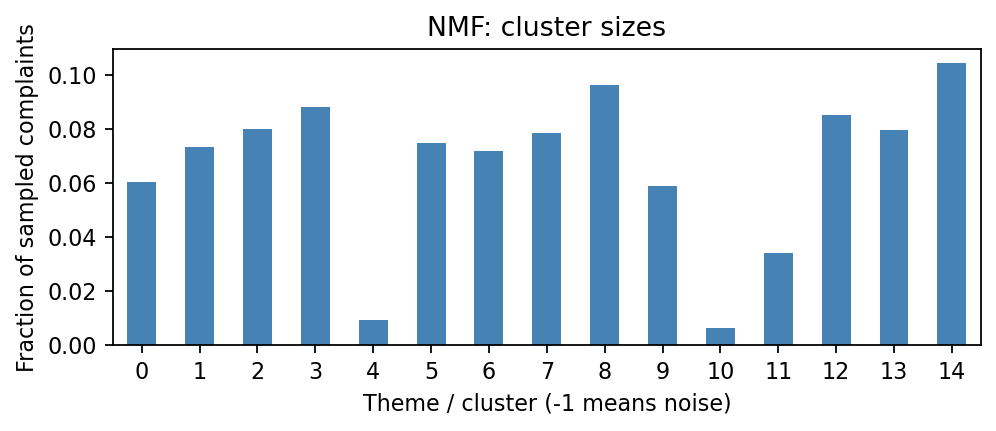

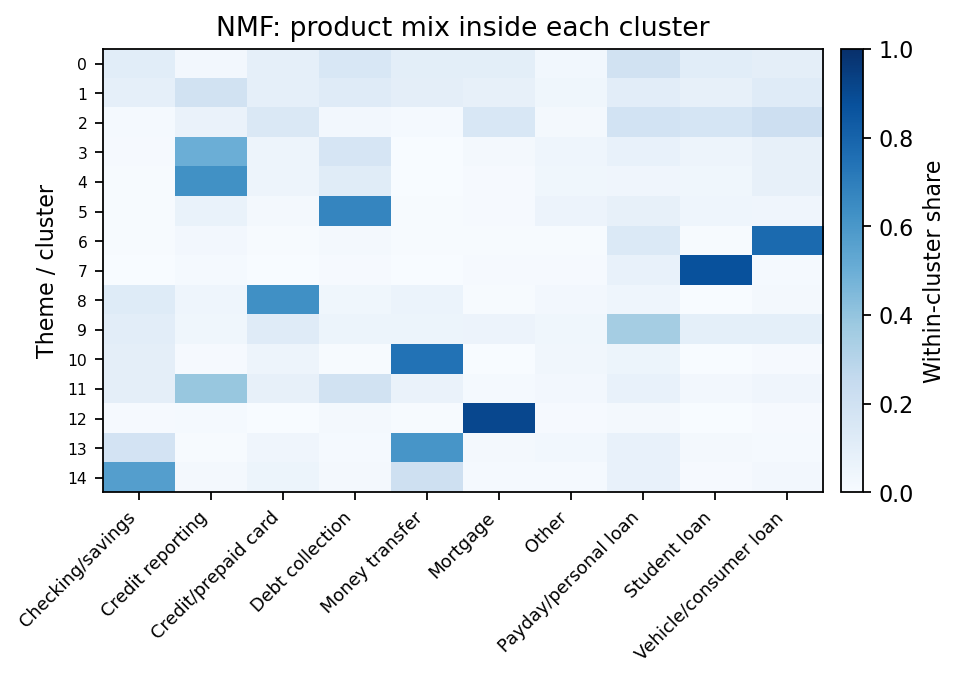

### lda

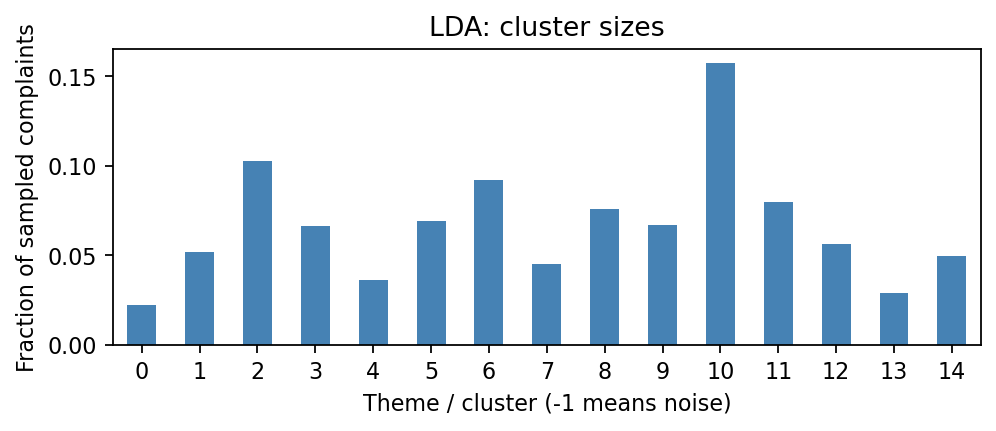

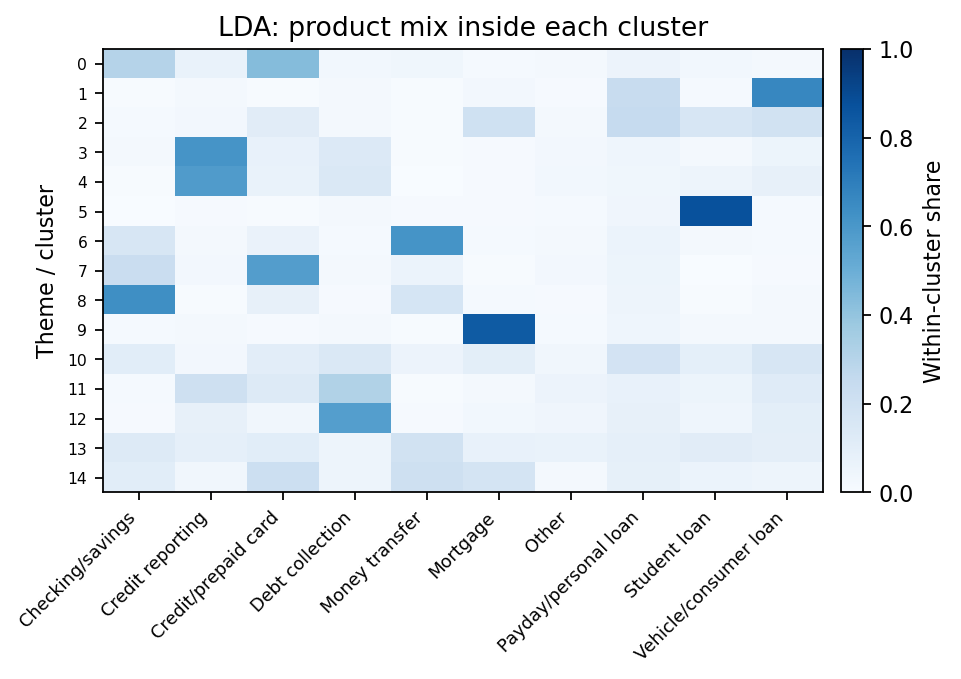

### kmeans

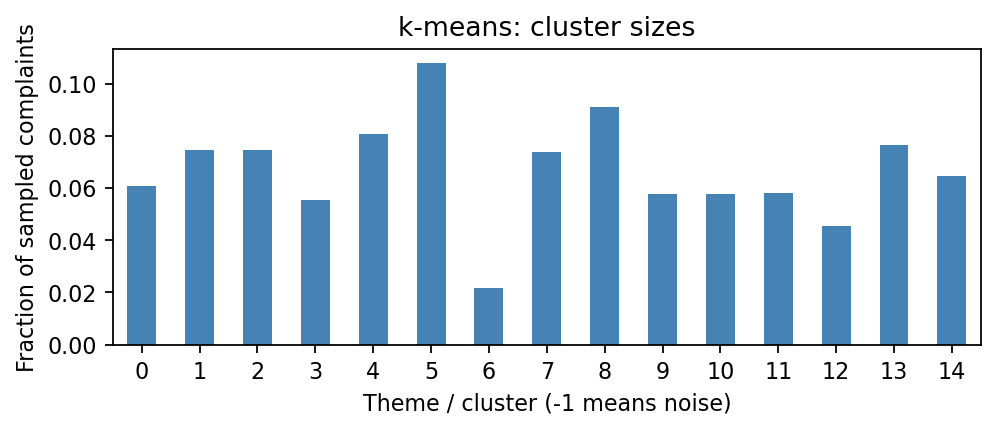

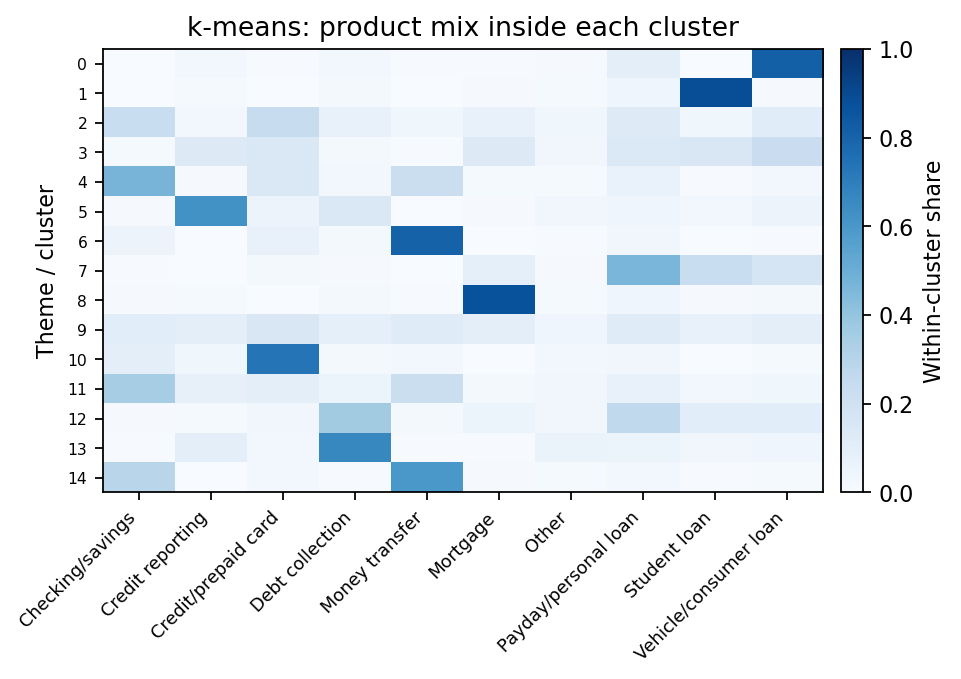

### umap_hdbscan

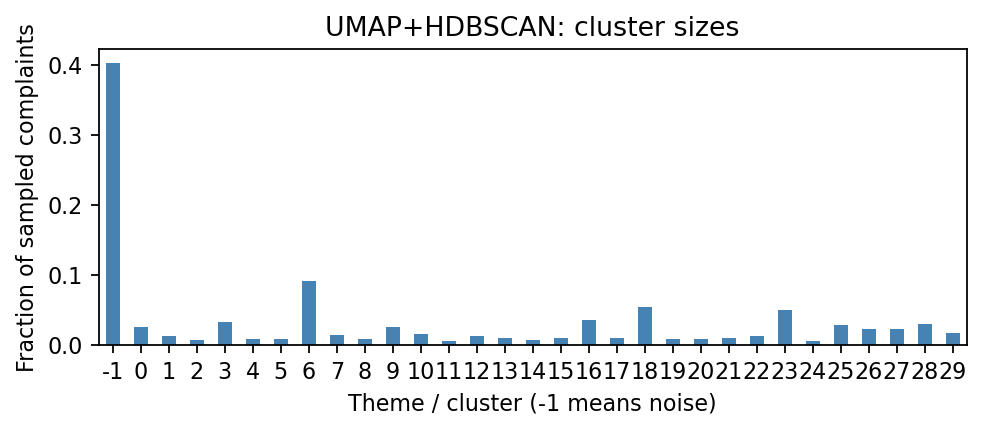

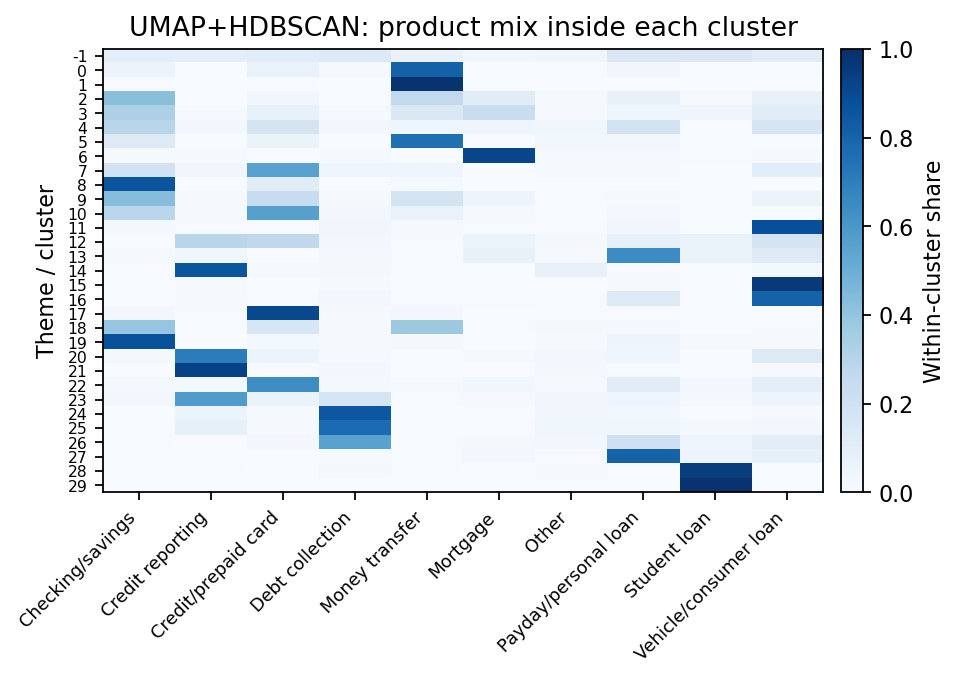

In [11]:
for method in ['nmf', 'lda', 'kmeans', 'umap_hdbscan']:
    display(Markdown('### ' + method))
    for view in ['sizes', 'products']:
        display(Image(filename=str(FIG / ('b_' + method + '_' + view + '.png'))))

## Relief by NMF theme

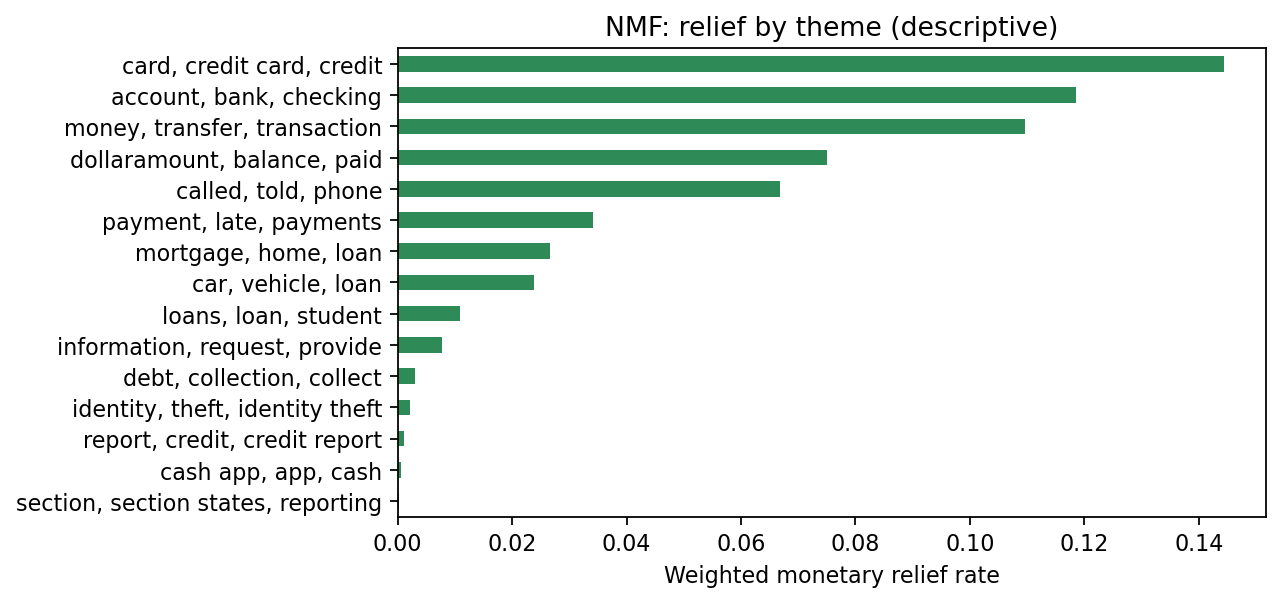

In [12]:
display(Image(filename=str(FIG / "b_nmf_relief_final.png")))

## Topic features and outcome prediction

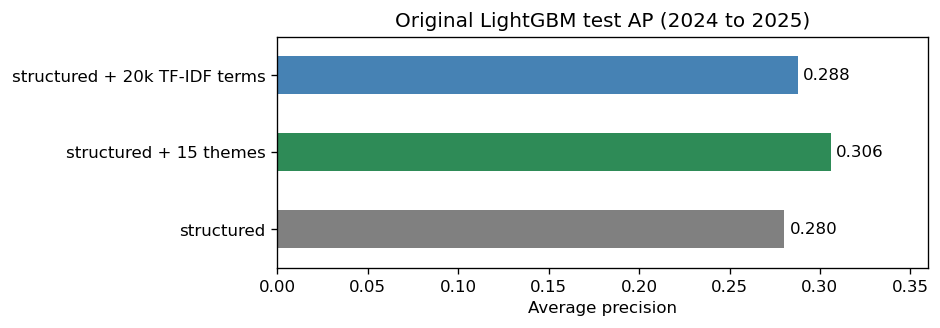

In [13]:
integration_plot = pd.read_csv(RES / "part_b_integration.csv").set_index("Unnamed: 0")["test PR-AUC"]
ax = integration_plot.plot.barh(figsize=(7, 2.5), color=["gray", "seagreen", "steelblue"],
                                title="Original LightGBM test AP (2024 to 2025)")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set(xlim=(0, .36), ylabel="", xlabel="Average precision")
plt.savefig(FIG / "b_integration.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()

### Plots

Redraw the saved results with larger labels and lossless images.

In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

FIG = Path("figures")
RES = Path("results")
plt.rcParams.update({
    "font.family": "Arial", "font.size": 10,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "figure.dpi": 120,
    "savefig.dpi": 600, "axes.spines.top": False,
    "axes.spines.right": False,
})



In [3]:
def save_figure(fig, name):
    fig.savefig(FIG / name, dpi=600, bbox_inches="tight", pad_inches=0.06, facecolor="white")
    plt.close(fig)

In [4]:
coordinates = RES / "b_umap_coordinates.csv"
if not coordinates.exists():
    docs = pd.read_parquet("data/part_b_sample.parquet")
    assignments = pd.read_csv(RES / "b_assignments.csv", dtype={"Complaint ID": str})
    assert docs["Complaint ID"].astype(str).tolist() == assignments["Complaint ID"].tolist()
    emb = np.load("data/part_b_embeddings.npy", mmap_mode="r")
    idx = np.random.default_rng(0).choice(len(docs), 20_000, replace=False)
    with threadpool_limits(limits=4):
        xy = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine",
                       random_state=0, n_jobs=1).fit_transform(emb[idx])
    pd.DataFrame({"sample_index": idx, "Complaint ID": docs.iloc[idx]["Complaint ID"].to_numpy(),
                  "x": xy[:, 0], "y": xy[:, 1],
                  "cluster": assignments.iloc[idx]["UMAP+HDBSCAN"].to_numpy(),
                  "product_group": docs.iloc[idx]["product_group"].to_numpy()}).to_csv(coordinates, index=False)

In [5]:
def topic_figures():
    coherence = pd.read_csv(RES / "part_b_coherence.csv", index_col=0)
    fig, ax = plt.subplots(figsize=(7.1, 1.7))
    for name in ["NMF", "LDA"]:
        ax.plot(coherence.index, coherence[name], "o-", label=name, markersize=4)
    ax.set(xlabel="Number of topics", ylabel="NPMI coherence", title="Topic-count sensitivity",
           xticks=coherence.index)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    save_figure(fig, "b_coherence.png")

    themes = ["Customer contact", "Information requests", "Payments", "Credit reports", "Legal wording",
              "Debt collection", "Vehicle loans", "Student loans", "Card charges", "Balances and fees",
              "Cash App", "Identity theft", "Mortgages", "Money transfers", "Bank accounts"]
    volumes = pd.read_csv(RES / "b_theme_volume.csv", index_col="year")
    fig, ax = plt.subplots(figsize=(7.1, 2.75))
    ax.stackplot(volumes.index, volumes.T.to_numpy(), baseline="sym", colors=plt.cm.tab20.colors[:15], labels=themes)
    ax.set(yticks=[], title="NMF theme volume over time", xlabel="")
    ax.set_xticks([2015, 2017, 2019, 2021, 2023, 2025])
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, fontsize=8.5, frameon=False,
              columnspacing=1.0, handlelength=1.0, labelspacing=0.3)
    fig.tight_layout()
    save_figure(fig, "b_theme_streamgraph.png")

    topics = pd.read_csv(RES / "b_topics.csv")
    nmf = topics[topics.method.eq("NMF")].set_index("theme")
    rates = nmf.weighted_relief.rename(index=dict(enumerate(themes))).sort_values()
    fig, ax = plt.subplots(figsize=(7.1, 2.85))
    ax.barh(rates.index, rates.values, color="seagreen")
    ax.set(title="Monetary relief by NMF theme", xlabel="Weighted monetary relief rate")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.tick_params(axis="y", labelsize=9.5)
    fig.tight_layout()
    save_figure(fig, "b_nmf_relief_final.png")

    assignments = pd.read_csv(RES / "b_assignments.csv")
    product_names = {"Checking/savings": "Checking/\nsavings", "Credit reporting": "Credit\nreporting",
                     "Credit/prepaid card": "Cards", "Debt collection": "Debt\ncollection",
                     "Money transfer": "Money\ntransfer", "Mortgage": "Mortgage", "Other": "Other",
                     "Payday/personal loan": "Personal\nloans", "Student loan": "Student\nloans",
                     "Vehicle/consumer loan": "Vehicle\nloans"}
    for method, stem in [("LDA", "lda"), ("k-means", "kmeans"), ("UMAP+HDBSCAN", "umap_hdbscan")]:
        sizes = assignments[method].value_counts(normalize=True).sort_index()
        fig, ax = plt.subplots(figsize=(7.1, 1.7))
        ax.bar(sizes.index.astype(str), sizes, color="steelblue")
        ax.set(title=f"{method}: group sizes", xlabel="Cluster (-1 = unassigned)" if stem == "umap_hdbscan" else "Topic / cluster",
               ylabel="Sample share")
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.tick_params(axis="x", labelsize=8.5)
        fig.tight_layout()
        save_figure(fig, f"b_{stem}_sizes.png")
        if stem == "umap_hdbscan":
            continue
        mix = pd.read_csv(RES / f"b_{stem}_products.csv", index_col="cluster")
        fig, ax = plt.subplots(figsize=(7.1, 2.65))
        im = ax.imshow(mix, aspect="auto", cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(mix.columns)), [product_names[c] for c in mix.columns], fontsize=8.5)
        ax.set_yticks(range(len(mix)), mix.index, fontsize=8.5)
        ax.set(title=f"{method}: product mix within each group", ylabel="Topic / cluster")
        colorbar = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.035)
        colorbar.set_ticks([0, 0.5, 1], labels=["0%", "50%", "100%"])
        fig.tight_layout()
        save_figure(fig, f"b_{stem}_products.png")

    coordinates = pd.read_csv(RES / "b_umap_coordinates.csv")
    fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.25))
    noise = coordinates.cluster.lt(0)
    axes[0].scatter(coordinates.loc[noise, "x"], coordinates.loc[noise, "y"], s=1.0, color="lightgray", rasterized=True)
    axes[0].scatter(coordinates.loc[~noise, "x"], coordinates.loc[~noise, "y"], s=1.0,
                    c=coordinates.loc[~noise, "cluster"], cmap="tab20", rasterized=True)
    axes[0].set_title("HDBSCAN clusters", fontsize=11)
    for group, frame in coordinates.groupby("product_group"):
        axes[1].scatter(frame.x, frame.y, s=1.0, label=group, rasterized=True)
    axes[1].set_title("Official product groups", fontsize=11)
    for ax in axes:
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, markerscale=5, fontsize=8.0,
               frameon=False, columnspacing=1.0, handlelength=1.0)
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    save_figure(fig, "b_umap.png")

    integration = pd.read_csv(RES / "part_b_integration.csv", index_col=0).iloc[:, 0]
    fig, ax = plt.subplots(figsize=(7.1, 1.65))
    labels = ["Metadata", "Metadata + 15 themes", "Metadata + TF-IDF"]
    bars = ax.barh(labels, integration, color=["gray", "seagreen", "steelblue"])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9.5)
    ax.set(xlim=(0, 0.36), xlabel="Test average precision", title="LightGBM: adding text features")
    fig.tight_layout()
    save_figure(fig, "b_integration.png")

In [6]:
topic_figures()